# Chapter 09 답안 양식. 회귀 분석으로 숫자 예측하기

> 이 내용을 `chapter09.ipynb`의 Markdown 셀로 작성합니다.

## 제출 정보

- 이름: 박재선
- GitHub ID: lilypark0930-lab
- 작성일: 2026.11.11
- 최종 제출 URL: https://github.com/lilypark0930-lab/llm-data-analysis-study/blob/main/chapter09/chapter09.ipynb



# 9장. 회귀 분석으로 숫자 예측하기

이 Notebook의 핵심은 높은 점수를 만드는 것이 아니라 다음 순서를 지키는 것입니다.

`예측 시점 → 누수 방지 → 시간 분할 → Train TimeSeriesSplit → 모델 선택 고정 → Final Test → Baseline 비교`

**Final Test 결과를 보고 모델을 고르지 않습니다.**

## 0. 실행 전 확인

Chapter09는 Chapter05의 오류 탐지용 전용 Raw가 아니라 **공통 프로젝트 `data/raw`**를 사용합니다. 먼저 프로젝트 루트에서 다음 명령을 실행해 관계 검증을 통과한 모델링 입력을 준비합니다.

```powershell
python scripts/prepare_ch09_data.py
```

이 명령은 공통 `data/raw`를 전처리하고 FK 관계를 검증한 뒤 `data/processed/*_clean.csv`를 생성합니다.

In [1]:
from pathlib import Path
import sys
import pandas as pd

CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = next(p for p in [CURRENT_DIR, *CURRENT_DIR.parents] if (p / 'src').is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORT_DIR = PROJECT_ROOT / 'reports'

from src.regression import (
    FEATURE_COLUMNS,
    FORBIDDEN_FEATURES,
    TARGET_COLUMN,
    build_feature_audit,
    build_leakage_checklist,
    build_regression_dataset,
    build_regression_validation,
    build_split_summary,
    create_prediction_result,
    cross_validate_regression_models,
    load_regression_source_data,
    make_regression_models,
    run_regression_analysis,
    save_regression_outputs,
    select_diagnostic_model,
    split_model_data_by_time,
    train_and_evaluate_models,
    validate_feature_columns,
)

print('PROJECT_ROOT:', PROJECT_ROOT)
print('PROCESSED_DIR:', PROCESSED_DIR)

PROJECT_ROOT: C:\dev\llm-data-analysis-study
PROCESSED_DIR: C:\dev\llm-data-analysis-study\data\processed


## 1. 예측 문제와 예측 시점

- Target: 주문 1건의 주문 상세 금액 합계 `order_total`
- 예측 시점: 주문 메타데이터와 고객의 비식별 특성은 알 수 있지만 주문 상세 수량·단가·금액은 모델에 제공하지 않는 시점
- 목표 계산 재료와 사후 정보, 식별자는 feature에서 제외합니다.

In [2]:
print('Target:', TARGET_COLUMN)
print('Allowed features:', FEATURE_COLUMNS)
print('Forbidden features:', sorted(FORBIDDEN_FEATURES))
validate_feature_columns()
print('Feature leakage gate: PASS')

Target: order_total
Allowed features: ['order_month', 'order_dayofweek', 'age', 'payment_method', 'gender', 'city']
Forbidden features: ['avg_unit_price', 'customer_id', 'item_count', 'line_total', 'order_id', 'order_status', 'order_total', 'product_id', 'quantity', 'total_quantity', 'unit_price']
Feature leakage gate: PASS


## 1. 예측 문제 정의

- **Target:** `order_total` — 주문 1건의 주문 상세 금액 합계 (`order_total = 같은 order_id의 line_total 합계`, `line_total = quantity × unit_price`)
- **예측 단위:** 주문 1건 (`order_id` 1개 = 1행)
- **예측 시점:** 주문이 생성되는 순간, 즉 주문 날짜·결제수단이 정해졌지만 **장바구니의 상품·수량·단가(주문 상세)는 아직 모델에 주어지지 않은 시점**
- **예측 시점에 알 수 있는 정보:** 주문 날짜에서 만든 `order_month`, `order_dayofweek`, 주문의 `payment_method`, 고객의 비식별 특성 `age`, `gender`, `city`
- **예측 시점에 알 수 없는 정보:** 주문 상세(`quantity`, `unit_price`, `line_total`, `product_id`)와 그로부터 계산되는 집계(`item_count`, `total_quantity`, `avg_unit_price`), 주문 이후에 확정되는 `order_status`(취소·환불 여부), 그리고 Target 자체인 `order_total`
- **이 예측이 필요한 이유 (교육용 가정):** 주문이 막 생성된 순간 주문 규모를 미리 추정할 수 있다면 고액 주문 우선 검수·배송 준비, 결제 이상 탐지 기준 등에 활용할 수 있다고 가정합니다. 다만 STEP 16에서 다시 검토하듯이, 주문 상세가 확정되면 이 값은 계산으로 정확히 알 수 있으므로 실제 업무 필요성은 제한적입니다.

> 실제 예측 순간에 사용할 수 없는 정보라면 데이터 파일에 존재하더라도 feature로 사용하지 않습니다.

### 나의 해석과 판단
주문 상세가 이미 확보된 시점이라면 `quantity × unit_price`를 더하기만 하면 `order_total`을 정확히 알 수 있으므로 예측 문제가 성립하지 않습니다. 따라서 **주문 상세가 확정되기 전, 주문 메타데이터와 고객 특성만 알려진 시점**을 예측 시점으로 정했습니다. 이 시점을 먼저 고정해야 어떤 컬럼이 "그 시점에 실제로 알 수 있는 정보"인지를 기준으로 feature를 판단할 수 있습니다. `order_status`처럼 데이터에는 존재하지만 주문 이후에 결정되는 값은, 시점을 정하지 않으면 무심코 들어가기 쉬운 사후 정보이기 때문에 시점 정의가 누수 방지의 출발점이라고 판단했습니다.

## 2. 검증된 전처리 데이터를 불러옵니다

In [3]:
data = load_regression_source_data(PROCESSED_DIR)
for name, frame in data.items():
    print(name, frame.shape)

customers (150, 6)
orders (300, 7)
order_items (764, 6)


## 3. 주문 단위 Target을 만들고 관계를 검증합니다

`line_total = quantity × unit_price`를 확인하고, 주문과 Target은 `one_to_one`, 주문과 고객은 `many_to_one` 관계가 깨지지 않는지 확인합니다.

In [4]:
model_data = build_regression_dataset(
    customers=data['customers'],
    orders=data['orders'],
    order_items=data['order_items'],
)
display(model_data.head())
print('Model rows:', len(model_data))

,order_id,customer_id,order_date,payment_method,order_status,order_month,order_dayofweek,order_total,gender,age,city
0,238,124,2025-09-15,bank_transfer,completed,9,0,361000,M,67,대구
1,79,62,2025-09-17,bank_transfer,refunded,9,2,283000,F,63,광주
2,12,98,2025-09-18,kakao_pay,completed,9,3,444000,F,61,인천
3,169,9,2025-09-18,kakao_pay,completed,9,3,448000,M,69,서울
4,152,62,2025-09-19,naver_pay,refunded,9,4,985000,F,63,광주


Model rows: 300


### 계산 기준

```text
line_total  = quantity × unit_price
order_total = 같은 order_id의 line_total 합계
```

- **line_total 불일치 건수:** 0건 (저장된 `line_total`을 그대로 믿지 않고 `quantity × unit_price`로 다시 계산해 비교)
- **line_total 검증 결과:** `line_total ≠ quantity × unit_price`인 행 0건 — 모든 주문 상세 행에서 계산 관계가 일치했습니다. 0 이하 금액도 없었습니다.
- **orders ↔ target 관계 검증 결과:** `one_to_one` 검증 통과. outer merge 결과 `both` 외의 행(상세 없는 주문, 부모 주문이 없는 상세)이 0건이었고, orders 300행 → 모델링 데이터 300행으로 행 손실·중복이 없었습니다.
- **orders → customers 관계 검증 결과:** `many_to_one` 검증 통과. `customers.customer_id`는 유일하며, 고객에 연결되지 않는 주문(`left_only`)은 0건이었습니다.

### 나의 해석과 판단
관계 검증 없이 병합만 수행하면 오류가 에러 없이 **조용히** 결과를 바꿉니다. 예를 들어 `customers`에 같은 `customer_id`가 두 번 있으면 해당 고객의 주문이 두 행으로 복제되어 주문 1건 = 1행이라는 예측 단위가 깨지고, 그 주문의 Target이 과도하게 학습에 반영됩니다. 반대로 inner join을 쓰면 상세가 없는 주문이나 고객이 없는 주문이 경고 없이 사라져, 특정 유형의 주문이 빠진 편향된 데이터로 모델을 평가하게 됩니다. 또 상세가 누락된 주문은 `order_total`이 실제보다 작게 계산됩니다. 이런 문제는 모델 점수만 봐서는 드러나지 않기 때문에, `validate=` 옵션과 미매칭 건수 확인으로 병합 단계에서 즉시 멈추게 해야 한다고 판단했습니다.

또한 Target 생성에 사용한 `quantity`, `unit_price`, `line_total`은 `order_total` 계산에만 쓰고, 모델 입력 `X`는 `FEATURE_COLUMNS` 6개로만 만들어 Target 재료와 Feature 입력을 분리했습니다.

## 4. Feature Audit을 확인합니다

In [5]:
feature_audit = build_feature_audit()
display(feature_audit)

,column,selected,role,reason
0,order_month,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
1,order_dayofweek,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
2,age,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
3,payment_method,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
4,gender,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
5,city,True,allowed_feature,교육용 예측 시점에 사용 가능하다고 가정
6,avg_unit_price,False,forbidden,주문 상세에서 만든 목표 대리 변수
7,customer_id,False,forbidden,고객 식별자
8,item_count,False,forbidden,주문 상세가 확인된 뒤 계산되는 사후 집계
9,line_total,False,forbidden,목표값을 구성하는 주문 상세 금액


| feature | 예측 시점 사용 가능 | Target 계산 재료 | 사후 정보/ID | 최종 사용 | 판단 이유 |
| --- | --- | --- | --- | --- | --- |
| order_month | O | X | X | **사용** | 주문 날짜는 주문 생성 시점에 알 수 있음 |
| order_dayofweek | O | X | X | **사용** | 주문 날짜에서 바로 계산 가능 |
| age | O | X | X | **사용** | 주문 전에 등록된 고객 특성 (비식별) |
| payment_method | O | X | X | **사용** | 주문 생성 시 선택되는 주문 메타데이터 (교육용 가정) |
| gender | O | X | X | **사용** | 주문 전에 등록된 고객 특성 (비식별) |
| city | O | X | X | **사용** | 주문 전에 등록된 고객 특성 (비식별) |
| order_total | X | O | X | 제외 | 예측 대상 자체 |
| line_total | X | O | X | 제외 | Target을 구성하는 주문 상세 금액 — 합하면 Target이 됨 |
| quantity | X | O | X | 제외 | Target 계산 재료 (`line_total = quantity × unit_price`) |
| unit_price | X | O | X | 제외 | Target 계산 재료 |
| item_count | X | O | O (사후 집계) | 제외 | 주문 상세가 확인된 뒤 계산되는 사후 집계 |
| total_quantity | X | O | O (사후 집계) | 제외 | 주문 상세에서 만든 Target 대리 변수 |
| avg_unit_price | X | O | O (사후 집계) | 제외 | 주문 상세에서 만든 Target 대리 변수 |
| order_status | X | X | O (사후 정보) | 제외 | 취소·환불 여부는 예측 시점 이후에 확정될 수 있음 |
| order_id | - | X | O (ID) | 제외 | 주문 식별자 — 숫자 크기에 의미가 없고 순서 정보가 섞일 수 있음 |
| customer_id | - | X | O (ID) | 제외 | 고객 식별자 — 일반 숫자 변수로 쓰면 개인 단위 암기 위험 |
| product_id | X | X | O (ID) | 제외 | 주문 상세가 확인되어야 알 수 있는 식별자 |

- **금지 feature overlap 개수:** 0 (`FEATURE_COLUMNS ∩ FORBIDDEN_FEATURES = ∅`, `validate_feature_columns()` PASS)
- **가장 위험하다고 판단한 feature:** `line_total` (및 그 재료인 `quantity`, `unit_price`)
- **이유:** `order_total`은 같은 `order_id`의 `line_total` 합계로 **정의**되므로, `line_total`이나 `quantity × unit_price`를 입력에 넣으면 모델이 예측하는 것이 아니라 계산식을 그대로 복원하게 됩니다. 이 경우 R²가 1에 가까운 "완벽한" 점수가 나오지만, 실제 예측 시점에는 이 값들이 존재하지 않으므로 운영에서는 전혀 쓸 수 없는 모델이 됩니다. 점수가 좋아 보이는 만큼 발견하기 어려운, 가장 직접적인 Target 누수입니다.

**금지 feature 유형별 정리**

| 유형 | 해당 feature |
| --- | --- |
| Target 자체 | `order_total` |
| Target 계산 재료 또는 대리 변수 | `line_total`, `quantity`, `unit_price`, `item_count`, `total_quantity`, `avg_unit_price` |
| 예측 시점 이후에 만들어지는 정보 | `order_status` |
| 식별자 | `order_id`, `customer_id`, `product_id` |

![Leakage 점검](images/step02_leakage.png)

## 5. 시간 순서로 Train / Final Test를 분리합니다

같은 달력 날짜를 양쪽에 나누지 않습니다. Final Test는 모델 선택이 끝날 때까지 사용하지 않습니다.

In [6]:
train_data, test_data = split_model_data_by_time(model_data, test_size=0.2)
split_summary = build_split_summary(train_data, test_data)
display(split_summary)
assert train_data['order_date'].max().normalize() < test_data['order_date'].min().normalize()
print('Chronological split gate: PASS')

,split,rows,ratio_pct,start_date,end_date
0,train,244,81.33,2025-09-15,2026-06-20
1,test,56,18.67,2026-06-21,2026-09-14


Chronological split gate: PASS


In [7]:
X_train = train_data[FEATURE_COLUMNS].copy()
X_test = test_data[FEATURE_COLUMNS].copy()
y_train = train_data[TARGET_COLUMN].copy()
y_test = test_data[TARGET_COLUMN].copy()
print('Train:', X_train.shape, 'Final Test:', X_test.shape)

Train: (244, 6) Final Test: (56, 6)


- **Train 시작일:** 2025-09-15
- **Train 종료일:** 2026-06-20
- **Train 행 수:** 244 (81.33%)
- **Final Test 시작일:** 2026-06-21
- **Final Test 종료일:** 2026-09-14
- **Final Test 행 수:** 56 (18.67%)
- **같은 달력 날짜 중복 여부:** 없음 — `train max date(2026-06-20) < final test min date(2026-06-21)`, 중복 일수 0

> 분할 비율이 정확히 80:20이 아닌 이유는 **주문일 단위**로 자르기 때문입니다. 같은 날짜의 주문을 Train과 Test에 나누어 넣지 않으려고 날짜 경계에서 분할했습니다.

### 분할 판단
이 모델은 실제로는 **과거 주문으로 학습해 앞으로 들어올 주문의 금액**을 예측하는 데 쓰입니다. 랜덤 분할을 하면 미래 기간의 주문이 Train에 섞여 모델이 "미래를 본 상태"로 평가되고, 같은 날짜·같은 시즌의 패턴이 양쪽에 동시에 들어가 성능이 실제보다 좋게 보일 수 있습니다. 시간 순서 분할은 운영 상황과 같은 조건(과거 → 미래)으로 평가하므로, Final Test 결과가 실제 사용 시 기대할 수 있는 성능에 더 가깝습니다. 또 이번 데이터에서는 Train에 7·8월 주문이 없고 Final Test가 6월 말~9월이라는 점도 확인했는데, 이런 계절 차이까지 그대로 드러나는 것이 시간 분할의 장점이자 이번 결과를 해석할 때 고려할 한계입니다. Final Test는 이 시점부터 **보호 구간**으로 두고, 아래 모델 선택 단계에서는 사용하지 않았습니다.

![시간 분할](images/step04_split.png)

## 5. 전처리 누수 방지 · Baseline과 후보 모델 · Train TimeSeriesSplit 후보 비교

### 전처리 누수 방지
- **숫자형 처리:** `order_month`, `order_dayofweek`, `age` → 결측치 median imputation → `StandardScaler`
- **범주형 처리:** `payment_method`, `gender`, `city` → 결측치 most_frequent imputation → `OneHotEncoder(handle_unknown="ignore")`
- **전처리 fit 범위:** 전처리기를 모델과 함께 하나의 `Pipeline`으로 묶었습니다. 교차검증에서는 각 Train Fold에서만, 최종 평가에서는 Train 기간 전체에서만 `fit`하고, Validation Fold와 Final Test에는 `transform`만 적용합니다.
- **전체 데이터에 먼저 fit하면 안 되는 이유:** 전체 데이터로 median, 평균·표준편차, 범주 목록을 먼저 계산하면 Final Test(미래 기간)의 분포 정보가 Train 전처리에 섞입니다. 예를 들어 미래 기간에만 나타나는 범주나 값의 범위가 스케일링 기준에 반영되어, 운영 시점에는 알 수 없는 정보를 모델이 미리 본 상태로 평가됩니다. 그러면 검증 점수가 실제보다 낙관적으로 나옵니다. `handle_unknown="ignore"`는 Train에 없던 범주가 미래에 나타나도 오류 없이 처리하기 위한 설정입니다.

### Baseline과 후보 모델
```text
Baseline Mean = DummyRegressor(strategy="mean")
Linear Regression
Random Forest
```

> **질문:** Random Forest가 복잡하다는 사실만으로 평균 예측보다 우수하다고 말할 수 있는가?
>
> **답:** 아니요. 모델이 복잡하다고 해서 미래 데이터에서 더 잘 맞는다는 보장은 없습니다. 입력 feature에 Target을 설명할 신호가 부족하면, 복잡한 모델은 오히려 Train의 우연한 패턴을 외워 평균 예측보다 나빠질 수 있습니다. 그래서 Baseline Mean을 **기준점**으로 두고, 실제 검증 결과(Train CV와 Final Test)로만 추가 가치를 판단합니다. 아래 결과에서도 Random Forest는 Baseline을 넘지 못했습니다.

### Train TimeSeriesSplit
**이 단계에서는 Final Test(`X_test`, `y_test`)를 사용하지 않습니다.**

## 6. Pipeline 후보 모델을 준비합니다

숫자형 결측 대체·표준화와 범주형 결측 대체·One-Hot Encoding은 모델 Pipeline 안에서 각 Train Fold로만 학습됩니다.

In [8]:
models = make_regression_models(random_state=42)
print(list(models))

['Baseline Mean', 'Linear Regression', 'Random Forest']


## 7. Train 기간의 TimeSeriesSplit으로 후보를 비교합니다

여기까지는 Final Test의 `y_test`를 모델 선택에 사용하지 않습니다.

In [9]:
cv_summary = cross_validate_regression_models(
    models=models,
    X_train=X_train,
    y_train=y_train,
)
display(cv_summary)

,model,n_splits,cv_MAE_mean,cv_MAE_std,cv_R2_mean
0,Baseline Mean,5,423004.808743,44153.043466,-0.022821
1,Random Forest,5,434988.775913,23875.590913,-0.110935
2,Linear Regression,5,476605.270739,74179.085725,-0.392969


## 8. 비베이스라인 모델 선택을 고정합니다

Linear Regression과 Random Forest 중 Train CV의 평균 MAE가 더 낮은 모델을 선택합니다. **이 시점까지 Final Test 성능은 보지 않습니다.**

In [10]:
selected_model_name = select_diagnostic_model(cv_summary)
print('Frozen selected model:', selected_model_name)

Frozen selected model: Random Forest


| 모델 | CV MAE 평균 | CV MAE 표준편차 | CV R² 평균 | 비고 |
| --- | ---: | ---: | ---: | --- |
| Baseline Mean | 423,004.81 | 44,153.04 | -0.0228 | 비교 기준 (선택 대상 아님). CV MAE가 세 후보 중 가장 낮음 |
| Linear Regression | 476,605.27 | 74,179.09 | -0.3930 | MAE 평균·표준편차 모두 가장 큼 |
| Random Forest | 434,988.78 | 23,875.59 | -0.1109 | 비베이스라인 중 MAE 최소, 표준편차도 최소 → **Selected** |

(TimeSeriesSplit `n_splits = 5`, Train 244행 내부에서만 계산)

### Train CV로 선택한 비베이스라인 모델
- **Selected Model:** Random Forest
- **선택 기준:** 비베이스라인 후보(`Linear Regression`, `Random Forest`) 중 Train TimeSeriesSplit `cv_MAE_mean`이 더 낮은 모델
- **근거가 된 cv_MAE_mean:** Random Forest 434,988.78 < Linear Regression 476,605.27. Fold 간 표준편차도 23,875.59로 Linear Regression(74,179.09)보다 작아 더 안정적이었습니다.
- **Final Test 결과를 보기 전에 선택했는가:** **예** — `select_diagnostic_model(cv_summary)`는 `cv_summary`만 입력으로 받으며, 선택 이후에만 `train_and_evaluate_models`로 Final Test를 사용했습니다.

> 주의 신호: Train CV 단계에서 이미 **Baseline Mean의 CV MAE(423,004.81)가 Random Forest(434,988.78)보다 낮았고**, 모든 후보의 CV R² 평균이 음수였습니다. 즉 선택된 모델조차 Train 기간 안에서 평균 예측보다 나은 근거가 없었다는 점을 Final Test 전에 기록해 둡니다.

### 나의 해석과 판단
CV 평균은 "평균적으로 얼마나 틀리는가"만 보여 주고, 표준편차는 **기간(fold)이 바뀔 때 성능이 얼마나 흔들리는가**를 보여 줍니다. 시간 순서 CV에서는 fold마다 다른 기간을 검증하므로, 표준편차가 크면 특정 기간에는 잘 맞고 다른 기간에는 크게 틀리는 모델이라는 뜻이고, 앞으로 올 미래 기간에서 어떤 성능이 나올지 예측하기 어렵습니다. 이번 결과에서 Linear Regression은 평균도 나쁘고 표준편차(74,179)도 커서 기간에 따라 불안정했고, Random Forest는 평균이 더 낮으면서 표준편차(23,876)도 가장 작아 선택 근거가 일관되었습니다. 또한 Baseline과 Random Forest의 평균 차이(약 11,984)는 Baseline의 표준편차(44,153)보다 작기 때문에, 평균 수치만으로 "어느 쪽이 확실히 낫다"고 단정할 수도 없습니다. 평균과 표준편차를 함께 봐야 차이가 의미 있는 차이인지 판단할 수 있습니다.

## 9. 이제 Final Test에서 Baseline과 고정 모델만 평가합니다

Final Test 결과가 기대와 다르더라도 같은 Test를 보고 다른 후보로 교체하지 않습니다.

In [11]:
model_comparison, predictions = train_and_evaluate_models(
    models=models,
    selected_model_name=selected_model_name,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
)
display(model_comparison)

,model,selection_role,train_MAE,test_MAE,test_RMSE,test_R2,MAE_improvement_vs_baseline_pct
0,Baseline Mean,baseline,416266.191884,443449.648712,522189.699620,-0.001121,0.00
1,Random Forest,selected_by_train_cv,327645.945199,464694.076952,550431.830272,-0.112339,-4.79


| 모델 | selection role | Train MAE | Test MAE | Test RMSE | Test R² | Baseline 대비 MAE 개선율 |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| Baseline Mean | baseline | 416,266.19 | 443,449.65 | 522,189.70 | -0.0011 | 0.00% |
| Frozen Selected Model (Random Forest) | selected_by_train_cv | 327,645.95 | 464,694.08 | 550,431.83 | -0.1123 | **-4.79%** |

![최종 회귀 평가](images/step06_final_metrics.png)

### 결과 관찰
- **MAE:** Frozen Model(Random Forest) 464,694원 / Baseline 443,450원
- **RMSE:** Frozen Model 550,432원 / Baseline 522,190원
- **R²:** Frozen Model -0.1123 / Baseline -0.0011
- **Baseline 대비 개선율:** -4.79% (개선되지 않음)

세부 관찰:
- Random Forest의 Final Test MAE(464,694)는 Baseline(443,450)보다 **약 21,244원 크고**, 개선율은 **-4.79%**로 Baseline보다 나빴습니다.
- Test RMSE도 Random Forest(550,432)가 Baseline(522,190)보다 큽니다.
- Test R²는 Baseline -0.0011, Random Forest -0.1123으로 둘 다 0 이하입니다.
- Random Forest의 Train MAE(327,646)는 Test MAE(464,694)보다 훨씬 작아 **Train과 Test의 격차가 약 137,000원**입니다. Baseline은 Train 416,266 → Test 443,450으로 격차가 작습니다.
- 이 결과는 Train CV에서 이미 보였던 신호(Baseline CV MAE < Random Forest CV MAE, CV R² 음수)와 같은 방향입니다.

### 나의 해석과 판단
- **Frozen Model이 baseline보다 실제로 개선되었는가?** 아니요. MAE 개선율이 -4.79%로, 현재 허용 feature만으로는 "학습 기간 평균 금액으로 일괄 예측"하는 것보다 나은 예측을 하지 못했습니다. Train MAE와 Test MAE의 큰 격차를 보면 Random Forest는 Train 기간의 우연한 패턴(고객 특성·날짜 조합)을 학습했고, 그것이 미래 기간에는 일반화되지 않은 것으로 보입니다.
- **MAE와 RMSE 차이에서 무엇을 볼 수 있는가?** Random Forest의 RMSE/MAE 비율은 약 1.18(Baseline도 약 1.18)로, 몇 건의 극단적 오차가 RMSE를 크게 끌어올린 형태는 아닙니다. 오히려 **대부분의 주문에서 수십만 원 단위의 오차가 고르게 발생**하고 있다는 뜻이며, 일부 이상치만 제거한다고 해결될 문제가 아니라 feature 자체에 금액을 설명할 정보가 부족하다는 해석이 더 자연스럽습니다.
- **R²는 어떻게 해석할 수 있는가?** R²는 "Test 기간의 실제 평균값으로 예측했을 때"보다 얼마나 나은지를 나타냅니다. Random Forest의 R² -0.1123은 **Test 평균으로 일괄 예측하는 것보다 오차 제곱합이 약 11% 더 크다**는 뜻입니다. Baseline의 R²가 0에 가까운(-0.0011) 이유는 Train 평균(855,295)이 Test 평균(837,821)과 비슷했기 때문입니다. R²가 음수라고 해서 코드가 틀린 것은 아니며, 누수 검증·시간 분할이 모두 PASS인 상태에서 나온 정직한 결과입니다.

### 업무·분석적 의미
주문 금액의 중앙값이 약 80만 원, 표준편차가 약 52만 원인데, 평균 오차가 약 46만 원이라는 것은 **예측값이 주문 금액의 대략적인 규모(소액/중간/고액)조차 구분해 주지 못한다**는 의미입니다. 이 수준의 예측을 재고 준비, 고객별 프로모션 금액 설정, 매출 예측 등에 사용하면 평균값을 쓰는 것보다도 판단이 나빠질 수 있습니다. 따라서 현재 결과의 업무적 가치는 "이 feature 조합으로는 주문 금액을 예측할 수 없다"는 사실을 누수 없이 확인했다는 점에 있습니다.

### 현재 한계
- Final Test가 56건뿐이라 MAE 차이(약 2만 원)가 표본 구성에 따라 바뀔 수 있으며, 이 결과만으로 두 모델의 우열을 확정할 수는 없습니다. 다만 "Random Forest가 Baseline보다 낫다"는 근거는 Train CV와 Final Test 어디에서도 나오지 않았습니다.
- Train에는 7·8월 주문이 없어, Final Test 기간의 계절 효과를 학습할 기회가 없었습니다.
- Final Test는 이번에 한 번 열었으므로, 이 결과를 보고 후보를 바꾸거나 feature를 조정하면 Final Test의 역할이 깨집니다. 추가 실험을 하려면 새로운 검증 설계나 새로운 미래 평가 구간이 필요합니다.

### 지표 읽기

- MAE: 평균적으로 얼마만큼 틀리는가
- RMSE: 큰 오차에 더 민감
- R²: 평균 예측 대비 설명력, 음수가 될 수 있음
- MAE 개선율: Dummy baseline 대비 고정 모델의 Final Test MAE 개선 정도

## 10. 실제값·예측값·잔차를 진단합니다

In [12]:
prediction_result = create_prediction_result(
    test_data=test_data,
    y_test=y_test,
    y_pred=predictions[selected_model_name],
    model_name=selected_model_name,
)
display(prediction_result.head(10))
print('주의: order_id가 포함된 이 표는 내부 진단용입니다.')

,order_id,order_date,actual_order_total,predicted_order_total,residual,abs_error,model
0,51,2026-08-22,1877000,5.415905e+05,1.335410e+06,1.335410e+06,Random Forest
1,21,2026-08-26,1767000,7.336590e+05,1.033341e+06,1.033341e+06,Random Forest
2,145,2026-08-03,1863000,8.557899e+05,1.007210e+06,1.007210e+06,Random Forest
3,96,2026-07-18,1690000,6.979246e+05,9.920754e+05,9.920754e+05,Random Forest
4,183,2026-07-30,1685000,7.835840e+05,9.014160e+05,9.014160e+05,Random Forest
5,15,2026-07-30,1677000,8.191082e+05,8.578918e+05,8.578918e+05,Random Forest
6,168,2026-08-18,10000,8.527183e+05,-8.427183e+05,8.427183e+05,Random Forest
7,282,2026-07-01,1566000,7.388317e+05,8.271683e+05,8.271683e+05,Random Forest
8,194,2026-07-26,257000,1.082731e+06,-8.257306e+05,8.257306e+05,Random Forest
9,179,2026-09-14,86000,8.390004e+05,-7.530004e+05,7.530004e+05,Random Forest


주의: order_id가 포함된 이 표는 내부 진단용입니다.


### 사례 1
- **실제값:** 1,877,000
- **예측값:** 541,590
- **residual:** +1,335,410 (과소예측)
- **absolute error:** 1,335,410 (Final Test 최대 오차)
- **관찰:** 8월 토요일 주문, 30대 여성, 서울, kakao_pay. 사후 진단으로 주문 상세를 보면 3개 상품·총 수량 13개로 구성된 고액 주문이었습니다. 모델 예측값은 Final Test 평균(약 84만 원)보다도 낮았습니다.
- **가능한 이유 후보:** (1) 금액을 크게 좌우하는 수량·상품 구성이 예측 시점 정보에 없어 고액 주문을 구분할 수단이 없음, (2) Train에 7·8월 주문이 없어 `order_month = 8`에 대한 학습 근거가 부족함, (3) 이 고객 특성 조합이 Train에서 우연히 소액 주문과 많이 겹쳤을 가능성.
- **추가 확인:** 같은 고객 특성 조합의 Train 주문 금액 분포, 8월 주문의 금액 분포를 다음 연도 데이터로 확인. 이 주문은 `order_status = cancelled`였는데, 취소 주문을 Target에 포함하는 것이 업무 정의에 맞는지 확인 필요(단, `order_status`는 feature로 쓰지 않음).

### 사례 2
- **실제값:** 1,767,000
- **예측값:** 733,659
- **residual:** +1,033,341 (과소예측)
- **absolute error:** 1,033,341
- **관찰:** 8월 수요일 주문, 50대 남성, 성남, bank_transfer. 주문 상세는 3개 상품·총 수량 11개로 사례 1과 비슷한 고액 다품목 주문이었습니다. 예측값은 평균 근처에 머물렀습니다.
- **가능한 이유 후보:** 사례 1과 마찬가지로 예측값이 평균 근처로 수렴하는 경향 — 현재 feature로는 고액 주문을 소액 주문과 구분하는 신호가 약해, 모델이 상위 금액대를 체계적으로 과소예측하는 것으로 보입니다(Final Test 상위 오차 10건 중 7건이 150만 원 이상 주문의 과소예측).
- **추가 확인:** 실제 금액 구간별(예: 상위 25%) 평균 residual을 계산해 과소예측이 체계적인지 확인. 고객의 **과거** 주문 금액(예측 시점 이전 기간만으로 계산한 값)을 feature로 쓸 수 있는지 검토.

### 사례 3
- **실제값:** 10,000
- **예측값:** 852,718
- **residual:** -842,718 (과대예측)
- **absolute error:** 842,718
- **관찰:** 8월 화요일 주문, 30대 남성, 대구, kakao_pay. 주문 상세는 단가 5,000원 상품 2개뿐인 최소 금액 주문이었는데, 모델은 평균 수준의 금액을 예측했습니다. 실제값 10,000은 전체 데이터의 최솟값입니다.
- **가능한 이유 후보:** 소액 주문을 구분할 정보(상품 종류·가격대)가 예측 시점 feature에 없음. 반대 방향으로도 같은 문제가 나타나, Final Test 예측값은 약 54만~108만 원 범위에만 분포해, 실제 금액 범위(10,000~1,877,000)보다 훨씬 좁습니다.
- **추가 확인:** 소액 주문이 특정 결제수단·고객군에 집중되는지 Train 기간에서 확인. 이 주문 역시 `cancelled` 상태여서, 테스트·취소성 주문이 Target 정의에 섞여 있지 않은지 데이터 정의를 확인.

> 위의 이유는 데이터가 직접 증명한 원인이 아니라 **가설**입니다. 주문 상세 구성은 사후 진단을 위해서만 확인했으며 feature로 사용하지 않았습니다.

## 11. 자동 Validation Evidence를 만듭니다

In [13]:
validation = build_regression_validation(
    train_data=train_data,
    test_data=test_data,
    cv_summary=cv_summary,
    selected_model_name=selected_model_name,
    model_comparison=model_comparison,
)
display(validation)
assert validation['status'].eq('PASS').all()

,check,value,status
0,forbidden_feature_overlap,0,PASS
1,strict_train_before_test,True,PASS
2,selected_model_exists_in_train_cv,True,PASS
3,final_test_contains_baseline,True,PASS
4,final_test_contains_frozen_selected_model,True,PASS
5,test_rows_for_r2,56,PASS


`reports/ch09_regression_validation.csv` 기준

| check | value | status |
| --- | --- | --- |
| forbidden_feature_overlap | 0 | PASS |
| strict_train_before_test | True | PASS |
| selected_model_exists_in_train_cv | True | PASS |
| final_test_contains_baseline | True | PASS |
| final_test_contains_frozen_selected_model | True | PASS |
| test_rows_for_r2 | 56 | PASS |

### FAIL 항목
- **없음** — 기본 판단 기준 `모든 status == PASS` 충족
- 6개 핵심 검사가 모두 PASS이므로 모델링 절차는 완료 상태입니다. (단, 절차가 올바르다는 것과 모델 성능이 사용 가능하다는 것은 별개이며, 성능 판단은 10번에서 합니다.)

### FAIL 원인
해당 없음

### 수정 내용
해당 없음

### 재검증 결과
11번 전체 재실행(`run_regression_analysis()` 새 호출)에서도 6개 항목 모두 PASS

## 12. Evidence·내부 진단·공개 보고서를 구분해 저장합니다

In [14]:
checklist = build_leakage_checklist()
output_paths = save_regression_outputs(
    model_data=model_data,
    split_summary=split_summary,
    feature_audit=feature_audit,
    cv_summary=cv_summary,
    selected_model_name=selected_model_name,
    model_comparison=model_comparison,
    prediction_result=prediction_result,
    validation=validation,
    checklist=checklist,
    report_dir=REPORT_DIR,
)
for name, path in output_paths.items():
    print(name, '->', path)

model_data_internal -> C:\dev\llm-data-analysis-study\reports\ch09_regression_model_data_internal.csv
split_summary -> C:\dev\llm-data-analysis-study\reports\ch09_regression_split_summary.csv
feature_audit -> C:\dev\llm-data-analysis-study\reports\ch09_regression_feature_audit.csv
cv_summary -> C:\dev\llm-data-analysis-study\reports\ch09_regression_cv_summary.csv
model_comparison -> C:\dev\llm-data-analysis-study\reports\ch09_regression_model_comparison.csv
predictions_internal -> C:\dev\llm-data-analysis-study\reports\ch09_regression_predictions_internal.csv
validation -> C:\dev\llm-data-analysis-study\reports\ch09_regression_validation.csv
checklist -> C:\dev\llm-data-analysis-study\reports\ch09_regression_checklist.csv
report -> C:\dev\llm-data-analysis-study\reports\ch09_regression_report.md
actual_vs_predicted_figure -> C:\dev\llm-data-analysis-study\reports\figures\ch09_actual_vs_predicted.png
residual_figure -> C:\dev\llm-data-analysis-study\reports\figures\ch09_residual_histogr

### 생성된 Evidence
- [x] `ch09_regression_split_summary.csv`
- [x] `ch09_regression_feature_audit.csv`
- [x] `ch09_regression_cv_summary.csv`
- [x] `ch09_regression_model_comparison.csv`
- [x] `ch09_regression_validation.csv`
- [x] `ch09_regression_checklist.csv`

### Internal 파일
- [x] `ch09_regression_model_data_internal.csv`
- [x] `ch09_regression_predictions_internal.csv`

### 공개 결과
- [x] `ch09_regression_report.md`
- [x] `ch09_actual_vs_predicted.png`
- [x] `ch09_residual_histogram.png`

### Evidence와 공개 범위
- **공개 가능한 Evidence:** `ch09_regression_split_summary.csv`, `ch09_regression_feature_audit.csv`, `ch09_regression_cv_summary.csv`, `ch09_regression_model_comparison.csv`, `ch09_regression_validation.csv`, `ch09_regression_checklist.csv`, `ch09_regression_report.md`, `figures/ch09_actual_vs_predicted.png`, `figures/ch09_residual_histogram.png` (식별자 없음)
- **Internal로만 유지할 파일:** `ch09_regression_model_data_internal.csv`, `ch09_regression_predictions_internal.csv`
- **Internal로 구분한 이유:** 아래 공개 범위 판단 참조

모델 검증(Validation PASS)과 결과 공개 범위 검토는 서로 다른 검증 항목이므로 따로 확인했습니다.

### 공개 범위 판단
`ch09_regression_predictions_internal.csv`와 `ch09_regression_model_data_internal.csv`에는 `order_id`(및 모델링 데이터의 `customer_id`)가 들어 있어, 다른 테이블과 다시 연결하면 **특정 주문·특정 고객의 실제 결제 금액, 예측 오차, 나이·성별·도시**까지 추적할 수 있습니다. 이는 개인정보·거래정보 노출에 해당할 수 있고, "어떤 고객의 주문을 모델이 크게 틀렸다"는 정보가 개별 고객에 대한 오해나 부적절한 조치로 이어질 위험도 있습니다. 반면 모델 평가에 필요한 것은 오차의 크기와 분포이지 누구의 주문인지가 아닙니다. 그래서 식별자가 있는 결과는 내부 진단용(Internal)으로 분리하고, 공개 보고서(`ch09_regression_report.md`)와 그래프에는 `order_id`를 제외한 `public_prediction_result`(날짜·실제값·예측값·잔차)만 포함했습니다. 이 Notebook에서도 7번의 사례 설명에는 `order_id`를 적지 않았습니다.

## 10. 최종 사용 판단

- [ ] 현재 수준에서 참고용 사용 가능
- [ ] 추가 검증 후 사용 가능
- [x] **현재 데이터로는 사용 보류**

### 판단 근거
1. **Baseline 대비 Final Test 성능:** 고정 모델(Random Forest)의 Test MAE 464,694는 Baseline 443,450보다 나쁘며(개선율 -4.79%), RMSE(550,432 vs 522,190)와 R²(-0.1123 vs -0.0011)도 모두 Baseline보다 나쁩니다. 평균값 일괄 예측보다 못한 모델을 사용할 이유가 없습니다.
2. **Train CV 안정성:** Train TimeSeriesSplit에서도 Baseline의 CV MAE(423,005)가 모든 비베이스라인 후보보다 낮았고, 모든 후보의 CV R² 평균이 음수였습니다. Final Test의 부진은 우연이 아니라 Train 기간에서 이미 예고된 결과입니다. 또한 Random Forest의 Train MAE(327,646)와 Test MAE의 격차가 커서 과적합 신호가 있습니다.
3. **절차의 신뢰성과 오류 패턴:** 누수 검증(overlap 0), 엄격한 시간 분할, Train CV 선택 고정, Baseline 비교가 모두 PASS이므로 이 낮은 성능은 코드 오류가 아니라 **현재 허용 feature에 주문 금액을 설명할 정보가 부족하다**는 정직한 결과입니다. 오차는 고액 주문의 체계적 과소예측과 소액 주문의 과대예측으로, 예측값이 평균 근처에 몰리는 패턴을 보였습니다.
4. **실제 업무에서 감당 가능한 오차 수준:** 평균 오차 약 46만 원은 주문 금액 중앙값(약 81만 원)의 절반을 넘습니다. 주문 규모별 우선 처리나 예산 판단에 쓰려면 적어도 소액·중간·고액을 구분할 수 있어야 하는데, 예측값이 54만~108만 원 사이에만 분포해 이 구분이 불가능하므로 업무에서 감당할 수 있는 수준이 아니라고 판단했습니다.

### 업무적 위험
이 모델을 사용하면 고액 주문은 크게 낮게, 소액 주문은 크게 높게 예측되어 평균값을 쓰는 것보다 더 큰 판단 오류(재고·프로모션 예산·매출 계획 등)를 만들 수 있습니다. 또한 점수를 높이기 위해 `quantity`, `unit_price`, `order_status` 같은 누수 feature를 넣으면 겉보기 성능은 크게 좋아지지만 운영 시점에는 그 값이 없으므로, 보고된 성능과 실제 성능의 차이로 더 큰 위험이 생깁니다. 낮은 성능을 숨기지 않고 "사용 보류"로 판단하는 것이 올바른 결과라고 봅니다.

### 현재 데이터의 한계
- 전체 300건(Train 244 / Final Test 56)으로 표본이 작아, Final Test 지표 자체의 변동성이 큽니다.
- 관측 기간이 약 1년(2025-09-15~2026-09-14)이라 계절성을 학습할 수 없고, Train에는 7·8월 주문이 전혀 없는데 Final Test는 대부분 7·8월입니다.
- 허용 feature 6개(날짜 2개, 결제수단, 고객 특성 3개)는 주문 금액을 결정하는 상품 구성·수량과 직접 관련이 약합니다.
- Target에 `cancelled`(64건)·`refunded`(52건) 주문이 포함되어 있어, "실제 매출 금액" 예측이라는 업무 정의와 다를 수 있습니다.
- 고객의 과거 구매 이력 같은 시점 기준 feature가 데이터에 준비되어 있지 않습니다.

### 다음 개선 우선순위
1. **예측 시점 이전 정보만으로 만든 고객 이력 feature 추가:** 각 주문일 **이전** 기간만으로 계산한 고객의 과거 평균 주문 금액·주문 횟수 등을 만들고, 시간 누수가 없는지 Feature Audit에 추가해 재검증합니다.
2. **데이터 기간·규모 확대:** 최소 2년 이상의 주문을 확보해 같은 월이 Train과 Final Test 양쪽 기간에 존재하도록 하고, 계절 효과를 확인합니다.
3. **Target 정의 재검토:** 취소·환불 주문을 Target에 포함할지 업무 담당자와 합의한 뒤(예: completed 주문만 대상), 같은 절차(시간 분할 → Train CV 선택 → Final Test 1회 평가)로 다시 평가합니다.

## 13. 전체 공통 함수를 새 실행으로 다시 확인합니다

셀의 메모리 상태가 아니라 공통 함수가 같은 순서를 재현하는지 확인합니다.

In [15]:
result = run_regression_analysis(
    processed_dir=PROCESSED_DIR,
    report_dir=REPORT_DIR,
    test_size=0.2,
    random_state=42,
)
print('Selected by Train CV:', result['selected_model_name'])
display(result['validation'])

Selected by Train CV: Random Forest


,check,value,status
0,forbidden_feature_overlap,0,PASS
1,strict_train_before_test,True,PASS
2,selected_model_exists_in_train_cv,True,PASS
3,final_test_contains_baseline,True,PASS
4,final_test_contains_frozen_selected_model,True,PASS
5,test_rows_for_r2,56,PASS


- **입력 준비 성공 여부:** 성공 — `prepare_ch09_data.py` 실행, FK 관계 검증 3개 항목 invalid_count 모두 0, `data/processed` 4개 파일 저장
- **회귀 스크립트 실행 성공 여부:** 성공 — `run_regression_analysis.py`가 오류 없이 끝났고, 11개 결과 파일이 저장되었습니다.
- **Train CV Selected Model:** Random Forest
- **Final Validation 전체 PASS 여부:** 6개 항목 모두 PASS
- **Notebook 결과와 스크립트 결과의 일관성:** 일치 — 스크립트 출력의 CV 요약(Baseline 423,004.81 / Random Forest 434,988.78 / Linear Regression 476,605.27), Final Test 지표(Test MAE 443,449.65 vs 464,694.08, 개선율 -4.79%), Validation 결과가 Notebook과 같았고, 위 셀의 `assert_frame_equal`로 cv_summary·model_comparison이 동일함을 확인했습니다(`random_state=42` 고정).

---

## 최종 체크

- [o] Target과 예측 시점을 정의했습니다.
- [o] Leakage Audit을 수행했습니다.
- [o] Target 계산과 관계 검증을 확인했습니다.
- [o] Train과 Final Test가 시간 순서로 엄격히 분리되었습니다.
- [o] 전처리가 Pipeline 내부에서 학습됩니다.
- [o] Train TimeSeriesSplit으로 후보를 비교했습니다.
- [o] Final Test 전에 Selected Model을 고정했습니다.
- [o] Final Test에서는 Baseline과 Frozen Model만 비교했습니다.
- [o] MAE, RMSE, R²를 함께 해석했습니다.
- [o] 대표 오차 사례를 관찰과 가설로 구분했습니다.
- [o] Validation Evidence가 모두 PASS입니다.
- [o] Internal 결과와 공개 결과를 구분했습니다.
- [o] 낮은 성능도 숨기지 않았습니다.
- [o] 전체 스크립트를 재실행했습니다.
- [o] 최종 Notebook URL을 제출합니다.

## 12. 현재 예측 요구사항의 한계 (STEP 16)

### 현재 Target
`order_total = order_id별 line_total 합계`, `line_total = quantity × unit_price` — 주문 1건의 주문 상세 금액 합계입니다.

### 이 값을 정확히 계산할 수 있는 시점
주문 상세(어떤 상품을 몇 개, 얼마에 담았는지)가 확정되는 순간입니다. 주문이 접수되면 `quantity`와 `unit_price`가 함께 기록되므로, 그 시점에는 모델 없이 곱하고 더하기만 하면 `order_total`을 **오차 없이** 알 수 있습니다.

### 현재 회귀 예측이 교육용으로는 의미가 있지만 실제 업무 예측으로는 제한적인 이유
- **교육용으로 의미 있는 점:** Target 재료(`quantity`, `unit_price`, `line_total`)가 데이터에 그대로 있어서 Feature Leakage가 무엇인지 분명하게 보여 주고, 시간 분할·Baseline 비교·MAE/RMSE/R² 해석·잔차 진단까지 회귀분석 전체 흐름을 안전하게 연습할 수 있습니다.
- **업무 예측으로 제한적인 이유:** "주문 상세는 모르지만 주문은 생성된 순간"은 실제 시스템에서 거의 존재하지 않는 시점입니다. 주문 상세를 알게 되는 순간 계산으로 정답을 얻을 수 있으므로, 회귀모델을 **사용할 수 있다**는 것과 **사용해야 할 이유가 있다**는 것이 다릅니다. 실제로 기본 실습 결과에서도 이 시점 정보만으로는 Baseline보다 나은 예측이 나오지 않았습니다.

### 더 의미 있는 예측 문제라면 무엇이 달라져야 하는가
- Target이 **예측 시점에 아직 발생하지 않은 미래의 값**이어야 합니다. (예: 다음 달 매출, 다음 기간 판매 수량)
- Feature는 예측 시점까지 **이미 발생한 과거 데이터**로만 만들어야 합니다.
- 예측 결과를 사용할 **의사결정**(재고·발주·예산·프로모션 계획 등)이 분명해야 합니다.
- Baseline도 문제에 맞게 "직전 기간 값", "과거 평균" 같은 현실적인 기준으로 바꿔야 합니다.

## 14. 해석

낮은 성능이나 음수 R²도 숨기지 않습니다. 현재 예측 시점에 허용한 정보가 약하다면 `현재 데이터로는 모델 사용 보류`도 올바른 결론입니다.

LLM이 만든 코드도 같은 예측 시점·누수·Pipeline·Train CV·Final Test 보호 기준으로 검토합니다.

## 15. 완료 체크

- [0] `python scripts/prepare_ch09_data.py`로 공통 모델링 입력을 준비했다.
- [0] Target과 예측 시점을 설명할 수 있다.
- [0] 금지 feature가 입력에 없음을 확인했다.
- [0] 같은 날짜가 Train과 Final Test에 동시에 들어가지 않는다.
- [0] 전처리는 Pipeline 내부에서 학습된다.
- [0] Train TimeSeriesSplit으로 후보를 비교했다.
- [0] Final Test 전에 Selected Model을 고정했다.
- [0] Final Test에서는 Baseline과 Frozen Model만 비교했다.
- [0] MAE, RMSE, R²를 함께 읽었다.
- [0] 내부 식별자 결과와 공개 보고서를 구분했다.
- [0] Validation Evidence가 모두 PASS다.

---

# Chapter 09 최종 확장 과제 결과

## 1. 새롭게 정의한 예측 문제 (STEP 17)

권장 예측 요구사항 3개를 데이터로 먼저 점검한 뒤 **권장 예측 요구사항 1 — 다음 달 카테고리별 completed 매출 예측**을 선택했습니다.

```text
이번 달 말까지 알고 있는 데이터 → 다음 달 category별 completed 주문 금액(next_month_sales) 예측
```

| 후보 | 데이터 점검 결과 | 판단 |
| --- | --- | --- |
| 1. 다음 달 카테고리별 매출 | 카테고리 7개 × 완전한 월 11개, 모든 달에 대부분 카테고리 매출 발생 | **선택** |
| 2. 상품별 판매 수량 | 상품 100개에 completed 주문 184건 → 상품 × 월 대부분이 0 | 샘플이 너무 희소해 보류 |
| 3. 고객별 향후 구매금액 | 고객 126명, 1인당 평균 주문 2.4건(중앙값 2건) | 가이드 기준(반복 구매 부족 시 억지로 선택하지 않음)에 따라 제외 |

선택한 문제가 직접 정의 조건을 만족하는지 확인했습니다.

- Target이 숫자형 연속값이다 → 월 매출(원)
- 예측 시점에는 Target을 아직 알 수 없다 → 다음 달 주문은 아직 발생하지 않음
- 과거 데이터만으로 Feature를 만들 수 있다 → 기준월까지의 월별 매출·주문 수·수량
- 미래 정보가 Feature에 들어가지 않는다 → 모든 Feature는 기준월(M) 이하 데이터로만 계산하고 코드로 검증
- 예측 결과를 활용할 업무 목적이 있다 → 카테고리별 재고·판매 계획

## 2. 이 예측이 필요한 이유
다음 달 카테고리별 매출을 미리 추정하면 **재고 확보량, 카테고리별 프로모션 예산, 판매 계획**을 월초 전에 세울 수 있습니다. 기본 실습의 `order_total`과 달리 이 값은 예측 시점(월말)에 **계산으로 알 수 없는 미래 값**이므로, 회귀모델을 사용할 이유가 있는 문제입니다.

## 3. Prediction Contract (STEP 18)

### 예측 목적
다음 달 카테고리별 completed 매출을 추정해 재고·판매 계획의 기준값으로 사용

### Target
`next_month_sales` = 예측 대상 월(M+1)에 해당 category 상품으로 발생한 **completed 주문**의 `line_total` 합계 (매출이 없으면 0)

### 예측 단위
category × month (카테고리 7개)

### 예측 시점
기준월 M의 마지막 날 마감 직후 (M월 주문까지 모두 알고 있음)

### Prediction Horizon
다음 1개월 (M+1월 전체)

### 사용할 Feature
기준월 M 이하 데이터로만 만든 값: `lag1_sales`(M월 매출), `lag2_sales`(M-1월), `lag3_sales`(M-2월), `roll3_mean_sales`(M-2~M월 평균), `hist_mean_sales`(관측 시작~M월 누적 평균), `lag1_orders`(M월 completed 주문 수), `lag1_quantity`(M월 판매 수량), `category`

### 사용하지 않을 Feature와 이유
- M+1월의 주문 수·수량·매출: 예측 대상 기간의 정보(미래 정보)
- 전체 기간으로 계산한 카테고리 평균: 미래 월의 매출이 평균에 섞이는 누수
- 대상 월의 달력 월(`target_month`의 1~12 값): 예측 시점에 알 수는 있지만, 관측이 약 1년뿐이라 Final Test 월(7·8월)이 Train에 한 번도 없어 계절 효과를 학습할 수 없고 숫자 외삽만 일어나므로 제외
- `order_id`, `customer_id`, `product_id`: 식별자

### 예측 결과의 실제 활용 방법
월말에 다음 달 카테고리별 예상 매출을 산출해 카테고리 담당자의 발주량·재고 수준 검토와 프로모션 예산 배분의 **참고 기준**으로 사용합니다. 단, 아래 평가에서 Baseline보다 나은 경우에만 사용합니다.

> 이번 달 말까지 알고 있는 데이터 → 다음 달 category별 total_sales 예측. 다음 달에 실제로 발생한 주문 정보는 Feature로 사용할 수 없습니다.

In [17]:
# 확장 과제 준비: 그래프·이미지 저장 설정 (앞 셀의 PROJECT_ROOT, PROCESSED_DIR 사용)
import matplotlib.pyplot as plt
from src.regression import configure_korean_font

configure_korean_font()
IMAGE_DIR = Path.cwd().resolve() / 'images'   # 제출용 이미지 (chapter09/images/)
IMAGE_DIR.mkdir(exist_ok=True)
print('IMAGE_DIR:', IMAGE_DIR)

IMAGE_DIR: C:\dev\llm-data-analysis-study\notebooks\ch09\images


## 4. Target과 Feature 설계 (STEP 19)

데이터 기간이 2025-09-15 ~ 2026-09-14여서 **첫 달(2025-09)과 마지막 달(2026-09)은 반쪽짜리 월**입니다. 일부 기간만 포함된 월을 그대로 쓰면 매출이 실제보다 작게 보이므로, 완전한 월(2025-10 ~ 2026-08, 11개월)만 사용합니다. 매출이 없는 category × month는 결측이 아니라 실제 0원으로 채웁니다.

In [18]:
# 확장 과제: 월별 category 매출 패널 만들기
ext_orders = pd.read_csv(PROCESSED_DIR / 'orders_clean.csv', parse_dates=['order_date'])
ext_items = pd.read_csv(PROCESSED_DIR / 'order_items_clean.csv')
ext_products = pd.read_csv(PROCESSED_DIR / 'products_clean.csv')

ext_sales = (
    ext_items.merge(ext_orders[['order_id', 'order_date', 'order_status']], on='order_id', how='left', validate='many_to_one')
    .merge(ext_products[['product_id', 'category']], on='product_id', how='left', validate='many_to_one')
)
assert ext_sales[['order_date', 'category']].notna().all().all(), '주문 또는 상품에 연결되지 않는 상세 행이 있습니다.'
ext_sales['month'] = ext_sales['order_date'].dt.to_period('M')

# 월별 주문 상태 분포 (completed 비율 확인)
display(pd.crosstab(ext_orders['order_date'].dt.to_period('M'), ext_orders['order_status'], margins=True))

# 완전한 월만 사용: 시작일이 1일이 아니면 첫 달 제외, 종료일이 말일이 아니면 마지막 달 제외
first_day, last_day = ext_orders['order_date'].min(), ext_orders['order_date'].max()
first_full = first_day.to_period('M') + (0 if first_day.day == 1 else 1)
last_full = last_day.to_period('M') - (0 if last_day.is_month_end else 1)
full_months = pd.period_range(first_full, last_full, freq='M')
print('관측 기간:', first_day.date(), '~', last_day.date())
print('사용할 완전한 월:', full_months.min(), '~', full_months.max(), f'({len(full_months)}개월)')

categories = sorted(ext_products['category'].unique())
grid = pd.MultiIndex.from_product([categories, full_months], names=['category', 'month']).to_frame(index=False)
monthly = (
    ext_sales.loc[ext_sales['order_status'].eq('completed') & ext_sales['month'].isin(full_months)]
    .groupby(['category', 'month'])
    .agg(sales=('line_total', 'sum'), orders=('order_id', 'nunique'), quantity=('quantity', 'sum'))
    .reset_index()
)
panel = (
    grid.merge(monthly, on=['category', 'month'], how='left', validate='one_to_one')
    .fillna({'sales': 0, 'orders': 0, 'quantity': 0})
    .sort_values(['category', 'month'])
    .reset_index(drop=True)
)
display(panel.pivot(index='month', columns='category', values='sales').astype(int))

order_status,cancelled,completed,refunded,All
order_date,,,,
2025-09,2,5,2,9
2025-10,6,19,2,27
2025-11,4,13,5,22
2025-12,8,23,2,33
2026-01,8,16,5,29
2026-02,6,7,4,17
2026-03,5,25,5,35
2026-04,4,16,7,27
2026-05,8,19,1,28


관측 기간: 2025-09-15 ~ 2026-09-14
사용할 완전한 월: 2025-10 ~ 2026-08 (11개월)


category,도서,뷰티,생활용품,스포츠,식품,전자기기,패션
month,,,,,,,
2025-10,774000,3204000,1162000,2961000,2481000,4377000,2011000
2025-11,844000,1130000,1610000,3610000,422000,2909000,496000
2025-12,1831000,4282000,4970000,4630000,1283000,3158000,931000
2026-01,1589000,2061000,2139000,2800000,1887000,3232000,564000
2026-02,582000,481000,259000,489000,1933000,916000,124000
2026-03,2957000,1996000,2318000,5184000,1895000,3282000,691000
2026-04,1536000,2310000,1193000,2412000,1457000,1230000,1408000
2026-05,1286000,2330000,2446000,5408000,2094000,1161000,1906000
2026-06,2310000,2063000,2660000,1212000,1889000,815000,1555000


In [19]:
# Feature: 모두 기준월 M 이하 데이터로만 계산 / Target: M+1월 매출
g = panel.groupby('category')
ext_feat = panel[['category', 'month']].copy()
ext_feat['target_month'] = ext_feat['month'] + 1
ext_feat['lag1_sales'] = panel['sales']
ext_feat['lag2_sales'] = g['sales'].shift(1)
ext_feat['lag3_sales'] = g['sales'].shift(2)
ext_feat['roll3_mean_sales'] = g['sales'].transform(lambda s: s.rolling(3).mean())
ext_feat['hist_mean_sales'] = g['sales'].transform(lambda s: s.expanding().mean())
ext_feat['lag1_orders'] = panel['orders']
ext_feat['lag1_quantity'] = panel['quantity']

ext_target = panel[['category', 'month', 'sales']].rename(columns={'month': 'target_month', 'sales': 'next_month_sales'})
ext_data = (
    ext_feat.merge(ext_target, on=['category', 'target_month'], how='inner', validate='one_to_one')
    .dropna()   # lag3가 없는 초기 2개월 제외
    .sort_values(['target_month', 'category'])
    .reset_index(drop=True)
)

EXT_NUMERIC = ['lag1_sales', 'lag2_sales', 'lag3_sales', 'roll3_mean_sales', 'hist_mean_sales', 'lag1_orders', 'lag1_quantity']
EXT_CATEGORICAL = ['category']
EXT_FEATURES = EXT_NUMERIC + EXT_CATEGORICAL
EXT_TARGET = 'next_month_sales'

# 누수 검증: Feature 기준월은 항상 Target 월보다 앞서야 함
assert (ext_data['month'] < ext_data['target_month']).all()
# 누수 검증: lag1_sales가 정말 기준월 매출인지, Target과 같은 값을 쓰지 않는지 재계산으로 확인
check = ext_data.merge(panel.rename(columns={'month': 'target_month', 'sales': 'chk'})[['category', 'target_month', 'chk']], on=['category', 'target_month'])
assert (check['chk'] == check[EXT_TARGET]).all()
assert set(EXT_FEATURES).isdisjoint({EXT_TARGET, 'target_month', 'order_id', 'customer_id', 'product_id'})
print('확장 과제 Feature 시점 검증: PASS')
print('모델링 행 수:', len(ext_data), '(category 7 ×', ext_data['target_month'].nunique(), '개 Target 월)')
display(ext_data.head(8))

확장 과제 Feature 시점 검증: PASS
모델링 행 수: 56 (category 7 × 8 개 Target 월)


,category,month,target_month,lag1_sales,lag2_sales,lag3_sales,roll3_mean_sales,hist_mean_sales,lag1_orders,lag1_quantity,next_month_sales
0,도서,2025-12,2026-01,1831000.0,844000.0,774000.0,1.149667e+06,1.149667e+06,4.0,14.0,1589000.0
1,뷰티,2025-12,2026-01,4282000.0,1130000.0,3204000.0,2.872000e+06,2.872000e+06,8.0,35.0,2061000.0
2,생활용품,2025-12,2026-01,4970000.0,1610000.0,1162000.0,2.580667e+06,2.580667e+06,13.0,62.0,2139000.0
3,스포츠,2025-12,2026-01,4630000.0,3610000.0,2961000.0,3.733667e+06,3.733667e+06,14.0,53.0,2800000.0
4,식품,2025-12,2026-01,1283000.0,422000.0,2481000.0,1.395333e+06,1.395333e+06,3.0,9.0,1887000.0
5,전자기기,2025-12,2026-01,3158000.0,2909000.0,4377000.0,3.481333e+06,3.481333e+06,4.0,24.0,3232000.0
6,패션,2025-12,2026-01,931000.0,496000.0,2011000.0,1.146000e+06,1.146000e+06,3.0,10.0,564000.0
7,도서,2026-01,2026-02,1589000.0,1831000.0,844000.0,1.421333e+06,1.259500e+06,3.0,10.0,582000.0


**Feature Audit (확장 과제)**

| Feature | 예측 시점 사용 가능 | 미래 정보 포함 | 최종 사용 | 이유 |
| --- | --- | --- | --- | --- |
| lag1_sales | O | X | **사용** | 기준월 M 매출, M월 마감 시 확정 |
| lag2_sales | O | X | **사용** | M-1월 매출 |
| lag3_sales | O | X | **사용** | M-2월 매출 |
| roll3_mean_sales | O | X | **사용** | M-2~M월 3개월 평균 (rolling이 현재 행 이하만 사용) |
| hist_mean_sales | O | X | **사용** | 관측 시작~M월 누적 평균 (expanding, 미래 월 미포함) |
| lag1_orders | O | X | **사용** | M월 completed 주문 수 |
| lag1_quantity | O | X | **사용** | M월 판매 수량 |
| category | O | X | **사용** | 예측 단위 자체, 고정 속성 |
| next_month_sales | X | O | 제외 | Target 자체 |
| M+1월 주문 수·수량 | X | O | 제외 | 예측 대상 기간의 정보 |
| 전체 기간 category 평균 | O(계산 가능) | O | 제외 | 미래 월 매출이 평균에 섞임 |
| target_month의 달력 월(1~12) | O | X | 제외 | 사용 가능하지만 Final Test 월(7·8월)이 Train에 없어 학습 불가 → 외삽 위험 |
| order_id / customer_id / product_id | - | X | 제외 | 식별자, 집계 단위와 맞지 않음 |

**데이터 기간 판단:** 완전한 월 11개 중 lag3를 만들 수 있는 Target 월은 2026-01 ~ 2026-08의 8개월뿐이라 모델링 행은 56개(7 × 8)입니다. 월 단위로는 샘플이 적다는 한계가 있지만, 가이드의 선택지 중 **카테고리 단위로 집계하여 샘플 확보** 방식을 택해 진행하고, 결과를 해석할 때 이 한계를 숨기지 않습니다. 주 단위로 바꾸면 샘플은 늘지만 주별 completed 주문이 평균 4건 미만이라 대부분 0원이 되어 오히려 잡음이 커진다고 판단했습니다.

## 5. Leakage Audit 결과
- Feature 기준월 < Target 월: 모든 행 PASS (`assert`)
- Target 재계산 일치: PASS
- 금지 컬럼(Target, 식별자, 대상 월 정보)과 Feature 목록 overlap: 0
- 전처리(StandardScaler, OneHotEncoder)는 Pipeline 내부에서 Train(또는 Train Fold)에만 fit

## 6. 시간 순서 평가 방법 (STEP 20)

```text
Target 월 2026-01 ~ 2026-06 (42행) → Train
Train 내부: 확장 윈도(expanding window) 월 단위 교차검증 4 fold
            (01~02 → 03 검증, 01~03 → 04, 01~04 → 05, 01~05 → 06)
Target 월 2026-07 ~ 2026-08 (14행) → Final Test (마지막에 한 번만 사용)
```

`TimeSeriesSplit`을 행 번호로 적용하면 같은 월의 카테고리 행이 Train과 검증에 나뉘어 들어갈 수 있으므로, **월 단위로 fold를 직접 정의**해 같은 Target 월이 양쪽에 동시에 들어가지 않게 했습니다.

**Baseline 정의 — Naive (직전 달 값):** `다음 달 매출 예측 = 이번 달(M) 매출(lag1_sales)`. 월말에 담당자가 별도 모델 없이 가장 쉽게 쓸 수 있는 기준이고, 매출 예측에서 흔히 쓰는 현실적인 비교 기준이므로 이것을 Baseline으로 정했습니다. 복잡한 모델은 적어도 "지난달만큼 팔린다"는 가정보다 나아야 사용할 가치가 있습니다.

후보 모델: `Linear Regression`, `Random Forest` — Train CV MAE 평균이 낮은 모델을 Final Test 전에 고정합니다.

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import numpy as np

ext_months = ext_data['target_month'].drop_duplicates().sort_values().tolist()
ext_test_months = ext_months[-2:]
ext_train = ext_data.loc[~ext_data['target_month'].isin(ext_test_months)].reset_index(drop=True)
ext_test = ext_data.loc[ext_data['target_month'].isin(ext_test_months)].reset_index(drop=True)
assert ext_train['target_month'].max() < ext_test['target_month'].min()
print('Train Target 월:', ext_train['target_month'].min(), '~', ext_train['target_month'].max(), f'({len(ext_train)}행)')
print('Final Test Target 월:', ext_test['target_month'].min(), '~', ext_test['target_month'].max(), f'({len(ext_test)}행)')

X_tr_ext, y_tr_ext = ext_train[EXT_FEATURES], ext_train[EXT_TARGET]
X_te_ext, y_te_ext = ext_test[EXT_FEATURES], ext_test[EXT_TARGET]

def ext_preprocessor():
    return ColumnTransformer([
        ('numeric', StandardScaler(), EXT_NUMERIC),
        ('categorical', OneHotEncoder(handle_unknown='ignore'), EXT_CATEGORICAL),
    ])

ext_models = {
    'Linear Regression': Pipeline([('preprocessor', ext_preprocessor()), ('model', LinearRegression())]),
    'Random Forest': Pipeline([
        ('preprocessor', ext_preprocessor()),
        ('model', RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1)),
    ]),
}

# 월 단위 expanding-window fold (Train 기간 내부만)
train_months = ext_train['target_month'].drop_duplicates().sort_values().tolist()
ext_folds = []
for i in range(2, len(train_months)):
    ext_folds.append((
        np.flatnonzero(ext_train['target_month'].isin(train_months[:i])),
        np.flatnonzero(ext_train['target_month'].eq(train_months[i])),
    ))
    print(f'fold {i - 1}: train {train_months[0]}~{train_months[i - 1]} → validate {train_months[i]}')

Train Target 월: 2026-01 ~ 2026-06 (42행)
Final Test Target 월: 2026-07 ~ 2026-08 (14행)
fold 1: train 2026-01~2026-02 → validate 2026-03
fold 2: train 2026-01~2026-03 → validate 2026-04
fold 3: train 2026-01~2026-04 → validate 2026-05
fold 4: train 2026-01~2026-05 → validate 2026-06


In [21]:
# Train CV 후보 비교 — Final Test는 사용하지 않음
rows = []
naive_mae = [mean_absolute_error(y_tr_ext.iloc[va], X_tr_ext['lag1_sales'].iloc[va]) for _, va in ext_folds]
naive_r2 = [r2_score(y_tr_ext.iloc[va], X_tr_ext['lag1_sales'].iloc[va]) for _, va in ext_folds]
rows.append({'model': 'Baseline Naive (lag1)', 'cv_MAE_mean': np.mean(naive_mae), 'cv_MAE_std': np.std(naive_mae), 'cv_R2_mean': np.mean(naive_r2)})
for name, model in ext_models.items():
    cv = cross_validate(model, X_tr_ext, y_tr_ext, cv=ext_folds,
                        scoring={'mae': 'neg_mean_absolute_error', 'r2': 'r2'}, error_score='raise')
    rows.append({'model': name, 'cv_MAE_mean': -cv['test_mae'].mean(), 'cv_MAE_std': cv['test_mae'].std(), 'cv_R2_mean': cv['test_r2'].mean()})
ext_cv_summary = pd.DataFrame(rows)
display(ext_cv_summary.round(4))

ext_selected = ext_cv_summary.loc[~ext_cv_summary['model'].str.startswith('Baseline')].sort_values('cv_MAE_mean').iloc[0]['model']
print('Train CV로 고정한 모델:', ext_selected)

,model,cv_MAE_mean,cv_MAE_std,cv_R2_mean
0,Baseline Naive (lag1),1.242143e+06,437037.7091,-4.6674
1,Linear Regression,1.534822e+06,281972.8445,-6.8379
2,Random Forest,1.011049e+06,446311.1411,-0.9896


Train CV로 고정한 모델: Random Forest


**Train CV 결과 (Final Test 개봉 전 기록)**

| 모델 | CV MAE 평균 | CV MAE 표준편차 | CV R² 평균 | 비고 |
| --- | ---: | ---: | ---: | --- |
| Baseline Naive (lag1) | 1,242,143 | 437,038 | -4.6674 | 비교 기준 |
| Linear Regression | 1,534,822 | 281,973 | -6.8379 | Baseline보다 나쁨 |
| Random Forest | 1,011,049 | 446,311 | -0.9896 | CV MAE 최소 → **Selected** |

- **Selected Model:** Random Forest (비베이스라인 중 CV MAE 평균 최소, Baseline보다도 약 23만 원 낮음)
- **Final Test를 보기 전에 선택했는가:** 예
- 단, fold별 표준편차(약 45만 원)가 평균 차이와 비슷한 크기이고 CV R² 평균도 음수여서, Train 기간에서도 안정적으로 좋은 모델이라고 보기는 어렵다는 점을 미리 기록합니다.

In [22]:
# Final Test: Baseline Naive vs Frozen Model만 평가
frozen = ext_models[ext_selected].fit(X_tr_ext, y_tr_ext)
ext_pred = frozen.predict(X_te_ext)

def reg_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
        'R2': r2_score(y_true, y_pred),
    }

ext_rows = []
for name, role, tr_pred, te_pred in [
    ('Baseline Naive (lag1)', 'baseline', X_tr_ext['lag1_sales'], X_te_ext['lag1_sales']),
    (ext_selected, 'selected_by_train_cv', frozen.predict(X_tr_ext), ext_pred),
]:
    m = reg_metrics(y_te_ext, te_pred)
    ext_rows.append({'model': name, 'selection_role': role, 'train_MAE': mean_absolute_error(y_tr_ext, tr_pred),
                     'test_MAE': m['MAE'], 'test_RMSE': m['RMSE'], 'test_R2': m['R2']})
ext_comparison = pd.DataFrame(ext_rows)
base_mae = ext_comparison.loc[0, 'test_MAE']
ext_comparison['MAE_improvement_vs_baseline_pct'] = ((base_mae - ext_comparison['test_MAE']) / base_mae * 100).round(2)
display(ext_comparison.round(4))

ext_result = ext_test[['category', 'target_month', EXT_TARGET, 'lag1_sales']].copy()
ext_result['predicted'] = ext_pred
ext_result['residual'] = ext_result[EXT_TARGET] - ext_result['predicted']
ext_result['abs_error'] = ext_result['residual'].abs()
display(ext_result.sort_values('abs_error', ascending=False).round({'predicted': 0, 'residual': 0, 'abs_error': 0}))
print('Final Test 기간 월별 실제 매출 합계:')
print(ext_result.groupby('target_month')[[EXT_TARGET, 'predicted']].sum().round(0))

,model,selection_role,train_MAE,test_MAE,test_RMSE,test_R2,MAE_improvement_vs_baseline_pct
0,Baseline Naive (lag1),baseline,1.250690e+06,1.014500e+06,1.270563e+06,-0.8028,0.00
1,Random Forest,selected_by_train_cv,5.015420e+05,1.061765e+06,1.338158e+06,-0.9997,-4.66


,category,target_month,next_month_sales,lag1_sales,predicted,residual,abs_error
10,스포츠,2026-08,103000.0,2061000.0,2790998.0,-2687998.0,2687998.0
11,식품,2026-08,134000.0,175000.0,2308544.0,-2174544.0,2174544.0
8,뷰티,2026-08,69000.0,2845000.0,1951318.0,-1882318.0,1882318.0
7,도서,2026-08,0.0,1928000.0,1668383.0,-1668383.0,1668383.0
4,식품,2026-07,175000.0,1889000.0,1684578.0,-1509578.0,1509578.0
13,패션,2026-08,637000.0,264000.0,2082393.0,-1445393.0,1445393.0
6,패션,2026-07,264000.0,1555000.0,1447116.0,-1183116.0,1183116.0
1,뷰티,2026-07,2845000.0,2063000.0,2198829.0,646171.0,646171.0
9,생활용품,2026-08,1579000.0,2126000.0,2060349.0,-481349.0,481349.0
12,전자기기,2026-08,1843000.0,1389000.0,1464444.0,378556.0,378556.0


Final Test 기간 월별 실제 매출 합계:
              next_month_sales   predicted
target_month                              
2026-07             10788000.0  12456705.0
2026-08              4365000.0  14326428.0


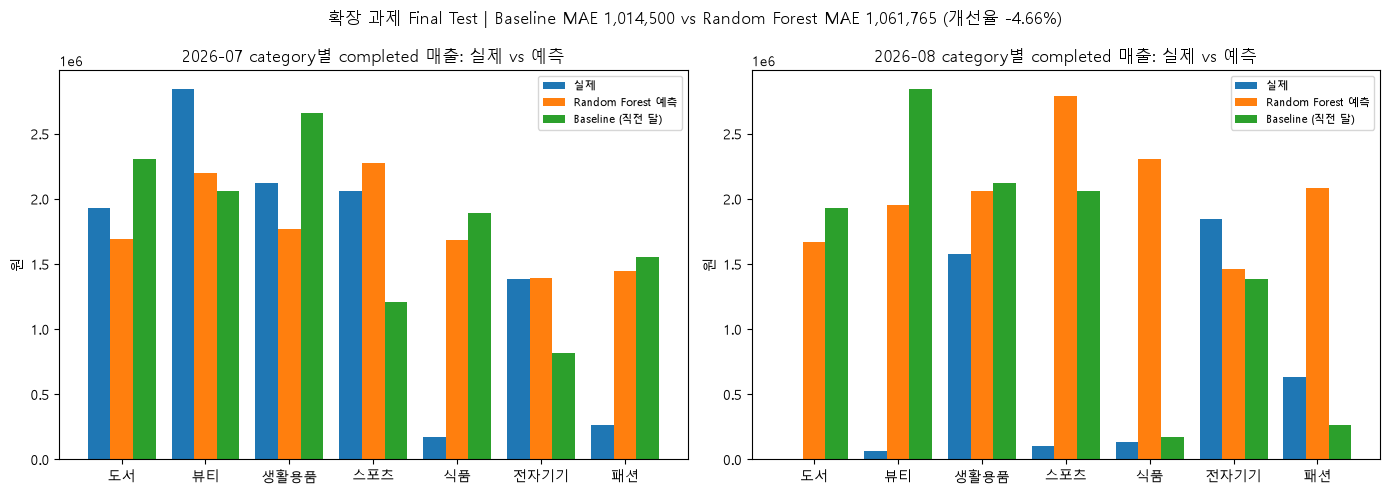

In [23]:
# 제출용 이미지: images/final_prediction_result.png
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, month in zip(axes, ext_test_months):
    part = ext_result.loc[ext_result['target_month'].eq(month)].set_index('category')
    x = np.arange(len(part))
    ax.bar(x - 0.27, part[EXT_TARGET], width=0.27, label='실제')
    ax.bar(x, part['predicted'], width=0.27, label=f'{ext_selected} 예측')
    ax.bar(x + 0.27, part['lag1_sales'], width=0.27, label='Baseline (직전 달)')
    ax.set_xticks(x, part.index)
    ax.set_title(f'{month} category별 completed 매출: 실제 vs 예측')
    ax.set_ylabel('원')
    ax.legend(fontsize=8)
row = ext_comparison.set_index('model')
fig.suptitle(
    f"확장 과제 Final Test | Baseline MAE {row.loc['Baseline Naive (lag1)', 'test_MAE']:,.0f} vs "
    f"{ext_selected} MAE {row.loc[ext_selected, 'test_MAE']:,.0f} (개선율 {row.loc[ext_selected, 'MAE_improvement_vs_baseline_pct']:.2f}%)"
)
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'final_prediction_result.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Baseline과 모델 결과

| 모델 | selection role | Train MAE | Test MAE | Test RMSE | Test R² | Baseline 대비 MAE 개선율 |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| Baseline Naive (lag1) | baseline | 1,250,690 | 1,014,500 | 1,270,563 | -0.8028 | 0.00% |
| Random Forest (Frozen) | selected_by_train_cv | 501,542 | 1,061,765 | 1,338,158 | -0.9997 | **-4.66%** |

![최종 예측 결과](images/final_prediction_result.png)

## 8. MAE / RMSE / R² 해석

### 결과 관찰
- **MAE:** Random Forest 1,061,765원 / Baseline 1,014,500원 — 카테고리 한 곳의 한 달 매출을 평균 약 106만 원 틀렸습니다.
- **RMSE:** Random Forest 1,338,158원 / Baseline 1,270,563원. RMSE/MAE 비율이 약 1.26으로, 일부 카테고리·월에서 큰 오차가 있었습니다.
- **R²:** Random Forest -0.9997 / Baseline -0.8028 — 둘 다 Final Test 평균값으로 일괄 예측하는 것보다 나빴습니다.
- **Baseline 대비 개선율:** -4.66% (개선되지 않음)
- Train CV에서는 Random Forest가 Baseline보다 약 23만 원 낮은 MAE를 보였지만, Final Test에서는 역전되었습니다. Random Forest의 Train MAE(약 50만 원)와 Test MAE(약 106만 원)의 차이도 컸습니다.

### 나의 해석과 판단
기본 실습과 마찬가지로 Train CV에서 고른 모델이 Final Test에서 Baseline을 넘지 못했습니다. 이번에는 Train CV 단계에서 Random Forest가 Baseline보다 나았기 때문에 선택 자체는 규칙대로 이루어졌지만, fold 간 표준편차가 커서 그 차이가 안정적인 우위는 아니었던 것으로 보입니다. R²가 음수인 이유는 Final Test 2개월(특히 8월)의 매출이 Train 기간과 다른 수준으로 움직였기 때문으로 보이며, 아래 오차 분석에서 확인합니다. 결과가 기대보다 낮아도 Final Test를 본 뒤 다른 후보로 교체하지 않았습니다.

## 9. 실제값과 예측값 비교 및 주요 오차

### 결과 관찰
- 오차가 큰 상위 7건은 모두 **실제보다 높게 예측(residual < 0)**했고, 그중 5건이 **2026-08** Target 월입니다. 예: 스포츠 8월 실제 103,000원 / 예측 2,790,998원(residual -2,687,998), 식품 8월 실제 134,000원 / 예측 2,308,544원, 뷰티 8월 실제 69,000원 / 예측 1,951,318원, 도서 8월 실제 0원 / 예측 1,668,383원.
- 2026-08의 completed 주문은 4건뿐이었습니다. 전체 주문은 16건(2월 17건과 비슷)이었지만, 그중 cancelled 6건·refunded 6건이어서 completed 비율이 약 25%로 다른 완전한 월(41~71%)보다 크게 낮았습니다.
- 7월에는 전자기기(실제 1,389,000 / 예측 1,389,790)처럼 거의 정확한 예측도 있었지만, 직전 달보다 매출이 급감한 식품(실제 175,000 / 예측 1,684,578)·패션(실제 264,000 / 예측 1,447,116)은 크게 과대예측했습니다. 즉 모델은 **매출 급감을 따라가지 못하는 패턴**을 보였습니다.

### 가설 (데이터가 직접 증명하지 않음)
- 8월 매출 급감은 과거 매출 패턴(lag·평균)으로는 예측할 수 없는 변화였을 수 있습니다. 관측 기간이 1년뿐이라 8월이 원래 비수기인지(계절성) 확인할 수 없습니다.
- 데이터 마지막 구간의 주문은 취소·환불 처리가 아직 진행 중이거나, 데이터 추출 시점의 상태가 반영된 것일 수 있습니다. 만약 그렇다면 최근 월의 completed 매출이 과소 집계되어 Target 자체가 불안정할 수 있습니다.
- 위 두 가지는 추가 데이터(다음 연도 8월, 주문 상태 변경 이력) 없이는 확인할 수 없으므로 사실로 단정하지 않습니다.

## 10. 업무적으로 사용할 수 있는가?

**판단: 현재 데이터로는 사용 보류**

- **왜 이 값을 미리 예측하려고 했는가?** 다음 달 카테고리별 재고·판매 계획을 월초 전에 세우기 위해서입니다.
- **현재 데이터로 이 예측이 가능한가?** 문제 정의는 타당하지만, 완전한 월 11개·모델링 56행으로는 카테고리별 월 매출의 변동을 학습하기에 데이터가 부족했습니다.
- **Baseline보다 실제로 나아졌는가?** 아니요. Final Test MAE 개선율 -4.66%로 "직전 달만큼 팔린다"는 단순 기준보다 나빴습니다.
- **오차 수준은 업무에서 감당할 수 있는가?** Final Test 기간 카테고리별 월 매출 평균이 약 108만 원인데 평균 오차가 약 106만 원이라, 재고·예산 판단의 기준으로 쓰기에는 오차가 너무 큽니다.
- **현재 모델을 실제 의사결정에 사용할 수 있는가?** 사용하지 않습니다. 현재 단계에서는 직전 달 실적을 참고하는 편이 오히려 낫고, 모델은 데이터를 더 모은 뒤 다시 평가해야 합니다.

## 11. 현재 데이터와 모델의 한계
- 관측 기간 약 1년, 완전한 월 11개 → lag 생성 후 모델링 행 56개, Final Test 14행으로 지표 변동성이 큽니다.
- 같은 달을 두 번 관측하지 못해 계절성을 학습·검증할 수 없습니다.
- 월별 completed 주문이 4~25건으로 적어, 주문 몇 건의 취소 여부만으로 카테고리 매출이 크게 바뀝니다.
- 마지막 구간의 주문 상태가 최종 확정된 값인지 알 수 없습니다.
- 기본 실습과 같은 원칙(누수 금지, 시간 분할, Train CV 선택 고정, Baseline 비교)을 지켰기 때문에, 이 결과는 데이터 한계를 정직하게 보여 주는 결과입니다.

## 12. 추가 데이터 또는 다음 개선 방향
1. **최소 2~3년의 월별 주문 데이터 확보:** 같은 월을 여러 번 관측해 계절성(전년 동월 매출)을 Feature로 쓰고, Baseline도 "전년 동월 값"과 비교합니다.
2. **주문 상태 확정 시점 정보 확보:** 취소·환불이 확정되는 기간을 확인해, 예측 시점에 상태가 확정된 주문만으로 lag Feature를 만들고 Target 정의를 안정화합니다.
3. **외부·계획 정보 추가 검토:** 다음 달 예정된 프로모션, 신상품 출시, 재고 수준처럼 **예측 시점에 이미 알 수 있는** 계획 정보를 Feature 후보로 추가하고, 같은 Leakage Audit과 시간 순서 평가로 다시 검증합니다.

---

## LLM 활용 기록 (STEP 22)

- **사용 목적:** Chapter09 실행 오류 해결, 확장 과제 Prediction Contract·Feature 설계·평가 코드 초안 작성, 결과 해석 문장 초안 작성
- **사용 도구:** Claude 
- **주요 Prompt 요약:**
  1. `ModuleNotFoundError: No module named 'src'` 오류 해결 요청
  2. `prepare_ch09_data.py` 실행 방법 질문

- **LLM이 제안한 내용:**
  - 공식 Notebook의 프로젝트 루트 탐색 코드가 `notebooks/` 바로 아래 위치만 가정해서 `notebooks/ch09/`에서 `src`를 찾지 못한다는 원인과, `src` 폴더가 있는 상위 폴더를 찾는 코드로 바꾸는 수정
  - 확장 과제로 "다음 달 카테고리별 completed 매출 예측" 선택, lag/rolling/expanding Feature, 직전 달 값 Baseline, 월 단위 expanding-window CV
- **그대로 사용하지 않고 수정한 부분과 수정 이유:**
  - 초안의 대표 오차 사례 설명에서 요일(월요일 → 실제 화요일)과 "상위 오차 10건 중 7건이 160만 원 이상"(실제로는 150만 원 이상 7건, 160만 원 이상 6건)이 실제 데이터와 달라, 날짜·금액을 다시 계산해 수정했습니다.
  - Notebook 실행 중 scikit-learn Pipeline의 HTML 표시가 Windows 기본 인코딩(cp949) 문제로 실패해, 텍스트 출력으로 바꿨습니다.
  - 확장 과제에서 처음에는 대상 월(1~12)을 Feature로 넣는 안도 검토했지만, Final Test 월(7·8월)이 Train에 없어 학습할 수 없으므로 제외했습니다.
  - 데이터 시작·끝 월이 일부 기간만 포함된 월이라는 점을 확인하고, 완전한 월만 사용하도록 수정했습니다.
  - 행 번호 기반 `TimeSeriesSplit` 대신, 같은 월이 Train과 검증에 나뉘지 않도록 월 단위 fold로 바꿨습니다.
- **최종 결과를 검증한 방법:**
  - `scripts/run_regression_analysis.py`를 터미널에서 새로 실행해 Notebook과 같은 Selected Model·지표·Validation이 나오는지 비교하고, Notebook 안에서도 `assert_frame_equal`로 일치를 확인했습니다.
  - Validation 6개 항목 PASS를 `assert`로 확인했습니다.
  - 확장 과제의 Feature 시점(기준월 < Target 월), Target 재계산 일치, 금지 컬럼 overlap 0을 `assert`로 확인했습니다.
  - 대표 오차 사례의 날짜·금액·주문 상세를 내부 진단 파일과 원본 데이터로 직접 다시 조회했습니다.
  - Kernel을 새로 시작해 Notebook 전체를 처음부터 실행했을 때 오류 없이 끝나는지 확인했습니다.

> LLM이 코드와 문장 초안을 만들었더라도, 예측 문제 선택·Feature 허용 여부·최종 사용 판단은 실제 실행 결과를 근거로 다시 확인한 뒤 확정했습니다.

---

## 최종 제출 (STEP 23)

제출 구조:

```text
chapter09/
├─ chapter09.ipynb        ← 이 Notebook
└─ images/
   ├─ step02_leakage.png
   ├─ step04_split.png
   ├─ step06_final_metrics.png
   └─ final_prediction_result.png
```

최종 제출 URL: https://github.com/lilypark0930-lab/llm-data-analysis-study/blob/main/chapter09/chapter09.ipynb

## 최종 제출 체크리스트

- [x] STEP 0~15 기본 회귀 실습을 완료했습니다.
- [x] 현재 order_total 예측 요구사항의 한계를 설명했습니다.
- [x] 미래에 발생하는 숫자형 Target을 새롭게 정의했습니다.
- [x] 예측 목적과 실제 활용 방법을 설명했습니다.
- [x] 예측 시점과 Prediction Horizon을 정의했습니다.
- [x] 예측 시점에 실제로 사용할 수 있는 Feature만 사용했습니다.
- [x] 새로운 Feature Leakage Audit을 수행했습니다.
- [x] 시간 순서에 따라 학습과 평가를 분리했습니다.
- [x] 문제에 맞는 Baseline을 정의했습니다.
- [x] Baseline과 회귀 모델을 비교했습니다.
- [x] MAE / RMSE / R²를 실제 결과로 해석했습니다.
- [x] 실제값과 예측값 및 대표 오차를 확인했습니다.
- [x] 낮은 성능도 숨기지 않고 기록했습니다.
- [x] 현재 데이터의 한계를 작성했습니다.
- [x] 모델의 실제 사용 가능성을 판단했습니다.
- [x] LLM 활용 내용과 사람이 검증한 내용을 구분했습니다.
- [x] Notebook을 처음부터 다시 실행해 오류가 없는지 확인했습니다.
- [x] GitHub에서 Notebook이 정상적으로 열리는지 확인했습니다. 
- [x] 최종 Notebook URL을 제출합니다.

